# Linear regression on 100 stocks

Rank 100 large US stocks by their next 21-day return relative to the group, using the price signals in `signals/core.py`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import yfinance as yf

from finance_project.signals import compute_signals, create_future_return_target
from finance_project.signals.core import SIGNALS

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 25)

In [2]:
TICKERS = [
    # Technology
    "AAPL", "MSFT", "NVDA", "ORCL", "CSCO", "IBM", "INTC", "QCOM", "TXN", "ADBE",
    "CRM", "ACN", "AMD", "MU", "AMAT", "ADI",
    # Communication
    "GOOGL", "CMCSA", "VZ", "T", "DIS", "NFLX",
    # Consumer discretionary
    "AMZN", "HD", "MCD", "NKE", "SBUX", "LOW", "TGT", "BKNG", "TJX", "F", "EBAY",
    # Consumer staples
    "PG", "KO", "PEP", "WMT", "COST", "MO", "CL", "MDLZ", "KMB", "GIS",
    # Health care
    "JNJ", "PFE", "MRK", "UNH", "ABT", "LLY", "BMY", "AMGN", "GILD", "MDT", "CVS",
    "TMO", "DHR", "CI",
    # Financials
    "JPM", "BAC", "WFC", "C", "GS", "MS", "AXP", "USB", "TRV", "MET", "AIG", "SCHW",
    "BLK", "PNC", "COF", "ALL",
    # Energy
    "XOM", "CVX", "COP", "SLB", "OXY", "EOG",
    # Industrials
    "GE", "HON", "MMM", "CAT", "BA", "UPS", "UNP", "LMT", "DE", "EMR", "FDX",
    # Utilities
    "NEE", "DUK", "SO", "D", "EXC",
    # Materials
    "APD", "NEM", "ECL",
    # Real estate
    "SPG", "AMT",
]
HORIZON = 21
SPLITS = {
    "train": ("2010-01-01", "2018-12-31"),
    "validation": ("2019-01-01", "2021-12-31"),
    "test": ("2022-01-01", "2026-09-30"),
}
ALPHAS = [0, 1e3, 1e4, 1e5, 1e6]  # ridge penalties; 0 is plain OLS
CACHE = Path("../data/stocks100_2009-01-01_2026-09-30.csv")
DAY = pd.Timestamp("2015-06-01")  # example date used to show intermediate tables

## 1. Prices

Yahoo returns a wide table (one column per ticker); reshape it to long `date, asset, close` rows and cache it.

In [5]:
if not CACHE.exists():
    raw = yf.download(TICKERS, start="2009-01-01", end="2026-10-01", auto_adjust=True)
    close = raw["Close"].rename_axis(index="date", columns="asset")
    close.stack().rename("close").reset_index().to_csv(CACHE, index=False)

prices = pd.read_csv(CACHE, parse_dates=["date"])
prices

,date,asset,close
0,2009-01-02,AAPL,2.714298
1,2009-01-02,ABT,17.199030
2,2009-01-02,ACN,24.225483
3,2009-01-02,ADBE,23.020000
4,2009-01-02,ADI,13.039446
...,...,...,...
446295,2026-09-30,USB,57.759998
446296,2026-09-30,VZ,45.169331
446297,2026-09-30,WFC,80.050003
446298,2026-09-30,WMT,103.919998


In [4]:
# The same data in wide form, as Yahoo returns it
prices.pivot(index="date", columns="asset", values="close").iloc[:3, :6]

asset,AAPL,ABT,ACN,ADBE,ADI,AIG
date,,,,,,
2009-01-02,2.714298,17.199024,24.225479,23.020000,13.039452,20.842695
2009-01-05,2.828852,16.903597,24.333406,23.129999,12.973159,20.472712
2009-01-06,2.782194,16.351284,24.031216,24.219999,13.602914,21.459337


## 2. Signals and target

Raw signal values per stock per day, and the return over the next 21 trading days.

In [5]:
names = list(SIGNALS)
target = f"ret_fwd_{HORIZON}d"

signals = compute_signals(prices, names)
signals[signals["date"] == DAY].head()

,date,asset,reversal_1d,mom_5d,mom_21d,mom_63d,mom_126d,mom_252d,vol_21d,vol_63d,vol_126d,downside_vol_21d,downside_vol_63d,drawdown_21d,drawdown_63d,drawdown_252d,skew_63d,skew_126d,downside_freq_21d,downside_freq_63d
161200,2015-06-01,AAPL,-0.001996,-0.015090,0.047425,0.015457,0.105905,0.468902,0.215751,0.210362,0.249493,0.124371,0.143533,-0.015090,-0.015090,-0.015090,0.032702,0.292494,0.523810,0.523810
161201,2015-06-01,ABT,-0.006996,-0.001835,0.054287,0.041727,0.117531,0.249190,0.169209,0.166187,0.181235,0.069145,0.102491,-0.008107,-0.008107,-0.008107,0.662099,0.713080,0.428571,0.444444
161202,2015-06-01,ACN,-0.001562,-0.002074,0.038209,0.066229,0.141736,0.209801,0.120406,0.207376,0.207609,0.058175,0.113879,-0.013031,-0.013031,-0.013031,1.899454,1.298374,0.428571,0.476190
161203,2015-06-01,ADBE,-0.009862,-0.002124,0.050092,0.001003,0.094409,0.237527,0.170067,0.193391,0.235917,0.079949,0.144927,-0.008565,-0.008565,-0.008565,-0.537450,1.468973,0.476190,0.428571
161204,2015-06-01,ADI,-0.011625,0.030758,0.118432,0.156973,0.284840,0.348168,0.240459,0.306418,0.261612,0.097641,0.155953,0.000000,0.000000,0.000000,2.048488,1.707036,0.428571,0.444444


In [6]:
future = create_future_return_target(prices, HORIZON)
future[future["date"] == DAY].head()

,date,asset,ret_fwd_21d
161200,2015-06-01,AAPL,-0.039145
161201,2015-06-01,ABT,0.002860
161202,2015-06-01,ACN,0.006133
161203,2015-06-01,ADBE,0.014273
161204,2015-06-01,ADI,-0.066327


In [7]:
# Join on (date, asset); drop the last 21 days, whose future is not known yet
data = signals.merge(future, on=["date", "asset"])
print(data.shape, "->", end=" ")
data = data.dropna(subset=[target])
print(data.shape)

(446300, 21) -> (444200, 21)


## 3. Rank signals and build `y`

Each signal becomes its rank among the 100 stocks on that date (−0.5 to +0.5; missing = 0 = middle).
The target `y` is the stock's return minus that day's average return.

In [8]:
data[names] = (data.groupby("date")[names].rank(pct=True) - 0.5).fillna(0)
data["y"] = data[target] - data.groupby("date")[target].transform("mean")

data[data["date"] == DAY][["date", "asset", "mom_21d", "vol_126d", "drawdown_252d", target, "y"]].head()

,date,asset,mom_21d,vol_126d,drawdown_252d,ret_fwd_21d,y
1612,2015-06-01,AAPL,0.36,0.31,0.32,-0.039145,-0.019476
6075,2015-06-01,ABT,0.39,-0.16,0.40,0.002860,0.022530
10538,2015-06-01,ACN,0.30,0.07,0.36,0.006133,0.025802
15001,2015-06-01,ADBE,0.38,0.26,0.39,0.014273,0.033942
19464,2015-06-01,ADI,0.47,0.35,0.48,-0.066327,-0.046658


## 4. Split by date

Drop the last 21 dates of train and validation so no target reaches into the next split.

In [9]:
parts = {}
for name, (start, end) in SPLITS.items():
    part = data[data["date"].between(start, end)]
    if name != "test":
        part = part[part["date"] < np.sort(part["date"].unique())[-HORIZON]]
    parts[name] = part

pd.DataFrame(
    {name: [part["date"].min(), part["date"].max(), len(part)] for name, part in parts.items()},
    index=["first date", "last date", "rows"],
).T

,first date,last date,rows
train,2010-01-04 00:00:00,2018-11-28 00:00:00,224300
validation,2019-01-02 00:00:00,2021-12-01 00:00:00,73600
test,2022-01-03 00:00:00,2026-08-31 00:00:00,116900


## 5. Model and metrics

Ridge regression in closed form: $\beta = (X^\top X + \alpha I)^{-1} X^\top y$.
Metrics are computed on one date per month so 21-day targets do not overlap.

In [10]:
def fit(part, alpha):
    X, y = part[names].to_numpy(), part["y"].to_numpy()
    return np.linalg.solve(X.T @ X + alpha * np.eye(len(names)), X.T @ y)


def predict(part, beta):
    return part.assign(pred=part[names].to_numpy() @ beta)


def monthly(part):
    return part[part["date"].isin(np.sort(part["date"].unique())[::HORIZON])]


def information_coefficients(part):
    """Per date: rank correlation between predicted and actual excess returns."""
    return part.groupby("date").apply(lambda g: g["pred"].corr(g["y"], method="spearman"))


def long_short(part):
    """Per date: mean y of the top 10% predictions minus the bottom 10%."""
    decile = part.groupby("date")["pred"].transform(
        lambda p: pd.qcut(p.rank(method="first"), 10, labels=False)
    )
    return part[decile == 9].groupby("date")["y"].mean() - part[decile == 0].groupby("date")["y"].mean()


def evaluate(part, beta):
    part = predict(part, beta)
    r2 = 1 - ((part["y"] - part["pred"]) ** 2).sum() / (part["y"] ** 2).sum()
    ic = information_coefficients(monthly(part))
    spread = long_short(monthly(part))
    periods = 252 / HORIZON
    return {
        "R² (%)": 100 * r2,
        "IC mean": ic.mean(),
        "IC t-stat": ic.mean() / ic.std() * np.sqrt(len(ic)),
        "IC > 0 (%)": 100 * (ic > 0).mean(),
        "L/S return (%/yr)": 100 * spread.mean() * periods,
        "L/S Sharpe": spread.mean() / spread.std() * np.sqrt(periods),
        "months": len(ic),
    }

## 6. Choose alpha on validation

Fit on train, score on validation, keep the alpha with the highest IC.

In [11]:
validation = pd.DataFrame(
    {alpha: evaluate(parts["validation"], fit(parts["train"], alpha)) for alpha in ALPHAS}
).T.rename_axis("alpha")
alpha = validation["IC mean"].idxmax()
print("chosen alpha:", alpha)
validation.round(3)

chosen alpha: 10000.0


,R² (%),IC mean,IC t-stat,IC > 0 (%),L/S return (%/yr),L/S Sharpe,months
alpha,,,,,,,
0.0,0.227,0.036,1.042,52.778,20.835,1.298,36.0
1000.0,0.231,0.040,1.094,52.778,25.082,1.399,36.0
10000.0,0.215,0.044,1.079,50.000,18.228,0.972,36.0
100000.0,0.119,0.037,0.830,55.556,20.704,0.942,36.0
1000000.0,0.021,0.036,0.773,58.333,22.340,0.953,36.0


## 7. Final model

Refit on train + validation with the chosen alpha. Only the test row is out-of-sample.

In [12]:
beta = fit(pd.concat([parts["train"], parts["validation"]]), alpha)
pd.DataFrame({name: evaluate(part, beta) for name, part in parts.items()}).T.round(3)

,R² (%),IC mean,IC t-stat,IC > 0 (%),L/S return (%/yr),L/S Sharpe,months
train,0.174,0.025,0.897,57.944,12.091,0.540,107.0
validation,0.413,0.052,1.053,55.556,23.605,0.844,36.0
test,0.376,0.066,1.947,60.714,18.701,0.614,56.0


In [13]:
# Coefficients in basis points of 21-day excess return per unit of rank (bottom to top stock)
pd.Series(beta * 1e4, index=names, name="bp").sort_values().round(1)

drawdown_252d       -33.8
downside_freq_63d   -16.3
drawdown_21d        -10.6
skew_126d            -8.3
drawdown_63d         -5.3
mom_5d               -0.4
downside_vol_63d      1.3
vol_63d               3.1
reversal_1d           5.1
skew_63d              6.7
mom_252d              9.6
downside_freq_21d    10.5
downside_vol_21d     11.9
vol_21d              13.8
mom_21d              13.9
mom_63d              17.7
mom_126d             21.4
vol_126d             40.9
Name: bp, dtype: float64

## 8. Inside the test evaluation

In [14]:
test = predict(parts["test"], beta)
test[["date", "asset", "mom_21d", "vol_126d", "pred", "y"]].head()

,date,asset,mom_21d,vol_126d,pred,y
3273,2022-01-03,AAPL,0.35,-0.01,0.000988,-0.023686
3274,2022-01-04,AAPL,0.32,-0.01,0.002734,-0.003674
3275,2022-01-05,AAPL,0.07,0.00,0.002831,0.011010
3276,2022-01-06,AAPL,-0.23,0.01,0.002653,0.024649
3277,2022-01-07,AAPL,-0.26,-0.01,0.002350,0.039159


In [15]:
test_monthly = monthly(test)
ic = information_coefficients(test_monthly)
spread = long_short(test_monthly)
pd.DataFrame({"IC": ic, "long-short": spread}).round(3)

,IC,long-short
date,,
2022-01-03,-0.212,-0.089
2022-02-02,-0.296,-0.085
2022-03-04,0.062,0.014
2022-04-04,-0.328,-0.053
2022-05-04,-0.024,0.047
2022-06-03,-0.503,-0.185
2022-07-06,0.487,0.079
2022-08-04,-0.100,0.061
2022-09-02,-0.032,-0.004


In [16]:
# One month: the 10 stocks predicted best and worst
first = test_monthly[test_monthly["date"] == test_monthly["date"].min()].sort_values("pred")
pd.concat([first.head(10), first.tail(10)])[["date", "asset", "pred", "y"]]

,date,asset,pred,y
431721,2022-01-03,VZ,-0.004645,0.048508
141626,2022-01-03,D,-0.004253,0.048120
159478,2022-01-03,DUK,-0.004056,0.024804
266590,2022-01-03,MCD,-0.004009,-0.013244
248738,2022-01-03,KO,-0.003994,0.041917
226423,2022-01-03,IBM,-0.003829,0.019108
235349,2022-01-03,JNJ,-0.003774,0.017384
244275,2022-01-03,KMB,-0.003695,-0.037600
378165,2022-01-03,SO,-0.003506,0.019601
284442,2022-01-03,MMM,-0.003492,-0.052125


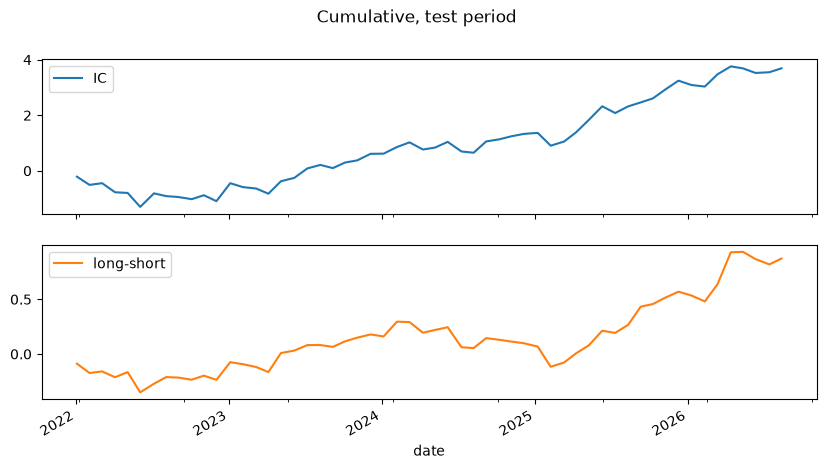

In [17]:
pd.DataFrame({"IC": ic, "long-short": spread}).cumsum().plot(subplots=True, figsize=(10, 5), title="Cumulative, test period");